In [54]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from mpmath import linspace

from functions_weather_data import DWDWeatherConfig, DWDWeatherFetcher
from pv_baukasten import PV_System, PV_TYPEN


In [55]:
print(__name__)


__main__


In [56]:
USE_EXISTING_WEATHER = True
weather_csv = "./Input/test_solarautobahn.csv"

In [57]:



# ------------------------------------------------------------
# 1) Wetterdaten laden (CSV ODER DWD)
# ------------------------------------------------------------
if USE_EXISTING_WEATHER:
    print("→ Verwende vorhandene Wetterdaten-CSV")
    weather_df = pd.read_csv(weather_csv, index_col=0, parse_dates=True)
    weather_df.index = pd.to_datetime(weather_df.index, utc=True).tz_convert(None)
else:
    print("→ Hole Wetterdaten neu vom DWD")
    cfg = DWDWeatherConfig(
        coords=(51.08579, 6.47554),
        start="2022-01-01",
        end="2022-12-31",
        station_id=None,
        auto_select=False,
        min_quality=0.95,
        save_path=weather_csv,
    )
    weather_df = DWDWeatherFetcher(cfg).run()

# if __name__ == "__main__":
#     # ------------------------------------------------------------
#     # 1) Wetterdaten vom DWD holen
#     # ------------------------------------------------------------
#     cfg = DWDWeatherConfig(
#         coords=(51.08579, 6.47554),
#         start="2022-01-01",
#         end="2022-12-31",
#         station_id=None,
#         auto_select=False,
#         min_quality=0.95,
#         save_path="./Input/wetterdaten_solarautobahn_2022.csv",
#     )
#     weather_df = DWDWeatherFetcher(cfg).run()

# ------------------------------------------------------------
# 2) PV-System anlegen (Geometrie + PV-Typen + Schrittweite)
# ------------------------------------------------------------
base_input = "./Input"
geojson_path = os.path.join(base_input, "geometrien", "agri_pv_short_line.geojson")
output_dir = os.path.join(base_input, "punkte")
os.makedirs(output_dir, exist_ok=True)

# hier kannst du auch mehrere Typen übergeben, z.B. [PV_TYPEN[0], PV_TYPEN[3], ...]
pv_system = PV_System(
    geojson_path=geojson_path,
    pvtypes=[PV_TYPEN[4]],   # 0 = Windschutzwand, 4 = Tracking
    step_size=50,             # Punktabstand in m
    weather_df=weather_df,
    base_output_dir=output_dir,
)

# ------------------------------------------------------------
# 3) Punkte + Azimut für alle gewählten PV-Typen generieren
# ------------------------------------------------------------
results = pv_system.generate_pv_points()


→ Verwende vorhandene Wetterdaten-CSV


In [58]:
results

{5:    azimut                  geometry  latitude  longitude  pv_type_id  \
 0     180  POINT (6.48859 51.07379)  51.07379    6.48859           5   
 
                   pv_type_name  tilt  
 0  Freifläche_bzw_Agri_geneigt    30  }

In [59]:
modul_anzahl = 300000
print("Berechnete PV-Typen:")
for pv_type in pv_system.pvtypes:
    print(" -", pv_type)


    print("\nJahresenergie je PV-Typ:")
for pv_type in pv_system.pvtypes:
    # CSV-Name so, wie ihn generate_pv_points gespeicher hat
    csv_name = f"punkte_{pv_type.id}_{pv_type.name}.csv".replace(" ", "_")
    csv_path = os.path.join(output_dir, csv_name)

    energy_kwh, total_ac = pv_system.simulate_pv_type_energy(pv_type, csv_path)
    print(f"  {pv_type.name}: 1 Modul:  {energy_kwh:.1f} kWh")
    energy_kwh_total = energy_kwh * modul_anzahl
    print(f"  {pv_type.name}: {energy_kwh_total/1000000:.1f} GWh")
    print(f'Anzahl Module: {modul_anzahl}')



Berechnete PV-Typen:
 - [5] Freifläche_bzw_Agri_geneigt

Jahresenergie je PV-Typ:
  Freifläche_bzw_Agri_geneigt: 1 Modul:  373.0 kWh
  Freifläche_bzw_Agri_geneigt: 111.9 GWh
Anzahl Module: 300000


In [63]:
total_ac_all = total_ac * modul_anzahl

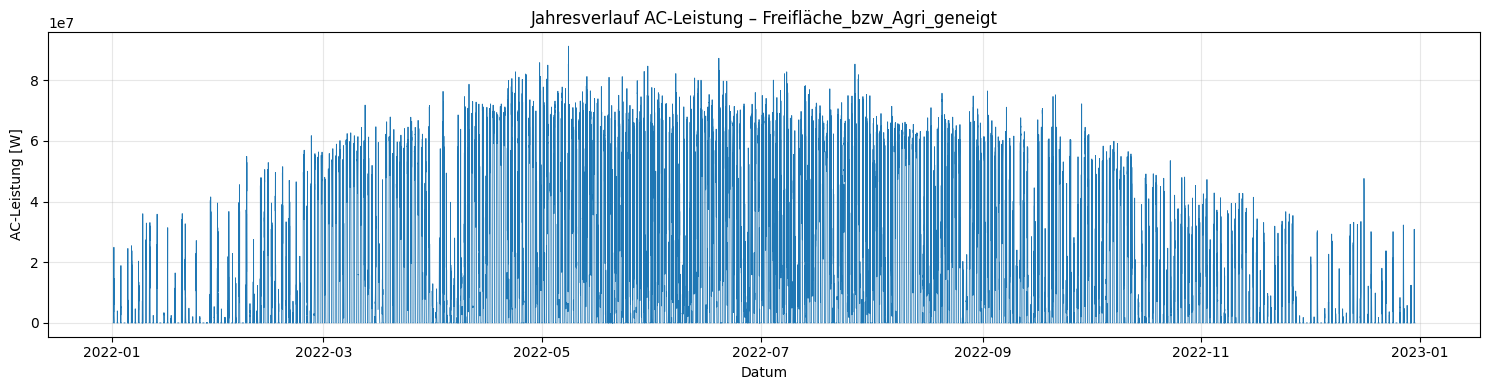

In [64]:
# ------------------------------------------------------------
# 4) Zeitreihe plotten
# ------------------------------------------------------------


# Plot der AC-Leistung über das Jahr
plt.figure(figsize=(15, 4))
plt.plot(total_ac.index, total_ac.values, linewidth=0.6)
plt.title(f"Jahresverlauf AC-Leistung – {pv_type.name}")
plt.xlabel("Datum")
plt.ylabel("AC-Leistung [W]")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

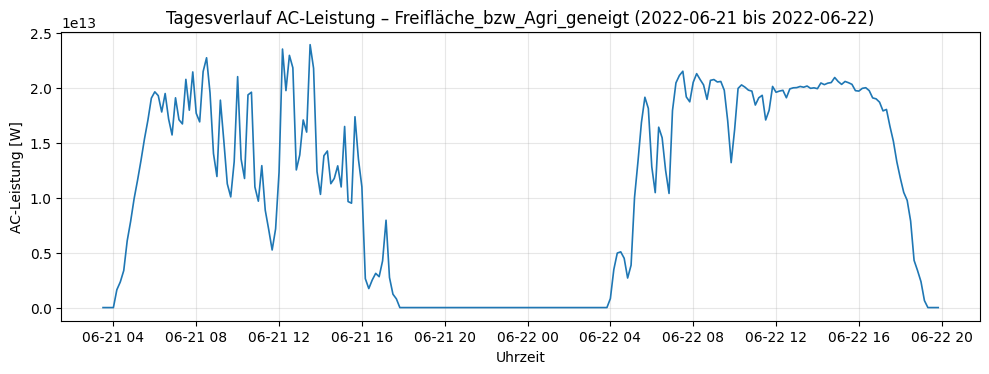

In [65]:
# ------------------------------------------------------------
# Zusatz: Tagesplot für einen Sommertag (z. B. 21. Juni)
# ------------------------------------------------------------
summer_day_start = "2022-06-21"
summer_day_end = "2022-06-22"
day_ac = total_ac_all.loc[summer_day_start:summer_day_end].copy()

summer_day_single = "2022-06-21"
#day_ac = total_ac.loc[summer_day_single].copy()


# Aufräumen für Plot:
day_ac = day_ac.dropna()
day_ac = day_ac.clip(lower=0)  # negative Werte (z.B. -0.1) auf 0 setzen

# Optional: nur Tagesstunden anzeigen (sieht meist besser aus)
#day_ac = day_ac.between_time("06:00", "22:00") #funktioniert nur mit einem sommer tag

plt.figure(figsize=(10, 4))
plt.plot(day_ac.index, day_ac.values, linewidth=1.2)
plt.title(f"Tagesverlauf AC-Leistung – {pv_type.name} ({summer_day_start} bis {summer_day_end})")
plt.xlabel("Uhrzeit")
plt.ylabel("AC-Leistung [W]")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
total_ac.sum()

671432861865.5483

In [68]:
total_ac_all.sum()

2.0142985855966454e+17

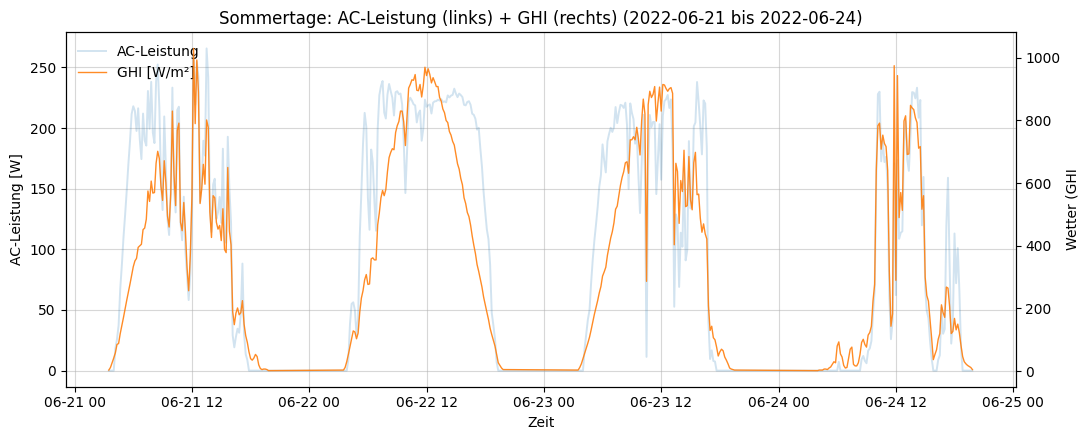

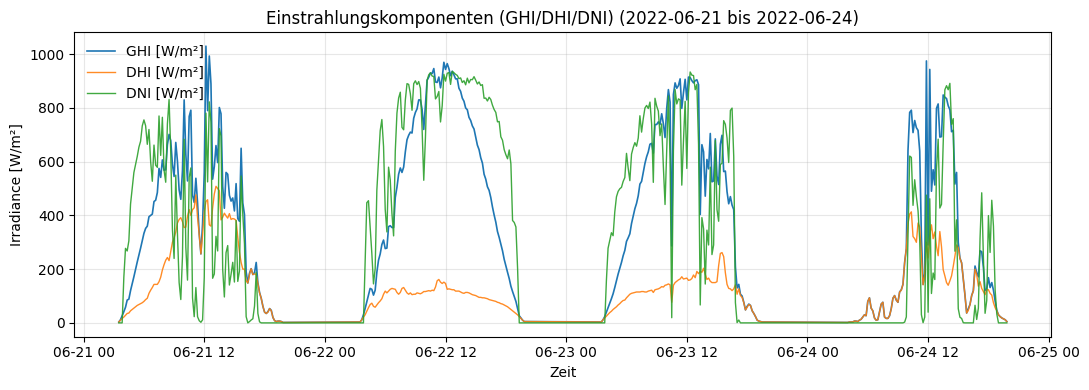

In [43]:
# ------------------------------------------------------------
# Plot 1: einzelne Sommertage – AC links, GHI (und optional Temp/Wind) rechts
# Plot 2: Vergleich GHI / DHI / DNI in einem Plot (gleicher Zeitraum)
# ------------------------------------------------------------
summer_day_start = "2022-06-21"
summer_day_end   = "2022-06-24"

# --- Daten zuschneiden ---
day_ac = total_ac.loc[summer_day_start:summer_day_end].dropna().clip(lower=0)

day_weather = weather_df.loc[summer_day_start:summer_day_end].copy()
# Wetter ans AC-Zeitgrid anpassen (falls Frequenzen abweichen)
day_weather = day_weather.reindex(day_ac.index).interpolate(method="time")

# =========================
# Plot 1: AC + GHI (rechts)
# =========================
fig, ax1 = plt.subplots(figsize=(11, 4.5))

# AC links
ax1.plot(day_ac.index, day_ac.values, linewidth=1.4, label="AC-Leistung",alpha = 0.2)
ax1.set_xlabel("Zeit")
ax1.set_ylabel("AC-Leistung [W]")
ax1.grid(True, alpha=0.5)

# Wetter rechts: GHI (und optional temp/wind)
ax2 = ax1.twinx()
ax2.plot(day_weather.index, day_weather["ghi"].values, linewidth=1.0, alpha=0.9, color='tab:orange', label="GHI [W/m²]")
# Optional dazu (wenn du's drin haben willst, sonst auskommentiert lassen)
#ax2.plot(day_weather.index, day_weather["temp_air"].values, linewidth=1.0, alpha=0.9, linestyle="--", label="T_air [°C]")
#ax2.plot(day_weather.index, day_weather["wind_speed"].values, linewidth=1.0, alpha=0.9, linestyle=":", label="Wind [m/s]")
ax2.set_ylabel("Wetter (GHI")# / °C / m/s)")

# gemeinsame Legende
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=False)

ax1.set_title(f"Sommertage: AC-Leistung (links) + GHI (rechts) ({summer_day_start} bis {summer_day_end})")
plt.tight_layout()
plt.show()

# ==========================================
# Plot 2: GHI / DHI / DNI gemeinsam ansehen
# ==========================================
fig, ax = plt.subplots(figsize=(11, 4.0))

ax.plot(day_weather.index, day_weather["ghi"].values, linewidth=1.2, label="GHI [W/m²]")
ax.plot(day_weather.index, day_weather["dhi"].values, linewidth=1.0, alpha=0.9, label="DHI [W/m²]")
ax.plot(day_weather.index, day_weather["dni"].values, linewidth=1.0, alpha=0.9, label="DNI [W/m²]")

ax.set_title(f"Einstrahlungskomponenten (GHI/DHI/DNI) ({summer_day_start} bis {summer_day_end})")
ax.set_xlabel("Zeit")
ax.set_ylabel("Irradiance [W/m²]")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()
